# Laporan Praktikum LP02: Harris Corner Detector
**Mata Kuliah:** Computer Vision Application (COMP6836001)  

---

### Anggota Kelompok:

| No | Nama Lengkap | NIM | Program Studi |
|:--:|:---|:---:|:---:|
| 1 | **MUHAMAD DICKY AZKIA** | 2802544596 | Computer Science |
| 2 | **RAKA SANTANG RABBANI** | 2802553915 | Computer Science |
| 3 | **NAUFAL HUGO ANANTA** | 2802531334 | Computer Science |
| 4 | **JORDAN RAVELINO DEVRIADI** | 2902716610 | Computer Science |
| 5 | **FERGIANT SHIHAB** | 2902735774 | Computer Science |

---

### Pembagian Tugas & Struktur Dokumen Praktikum:
Notebook ini menyajikan implementasi lengkap, analisis teoritis, dan evaluasi eksperimental algoritma **Harris Corner Detection** berdasarkan spesifikasi pada dokumen panduan praktikum `LP02 - Team Assignment Praktikum.pdf`:

* **Soal 1**: 
  * Perhitungan Sum of Squared Differences (SSD) / Corner Score $E(u,v)$ dengan zero-padding.
  * Formulasi aproksimasi deret Taylor terhadap pergeseran citra.
  * Komputasi turunan spasial citra ($I_x, I_y$) dan perkalian produk gradien ($I_{xx}, I_{yy}, I_{xy}$) menggunakan operator Sobel.
* **Soal 2**:
  * *Raka Santang Rabbani*: Rekonstruksi Struktur Tensor Matriks Harris (Second-Moment Matrix $M$) dengan pembobotan window ($w(u,v)$) serta formulasi Corner Response Measure $R = \det(M) - k \cdot (\text{trace}(M))^2$.
  * *Naufal Hugo Ananta*: Implementasi Ambang Batas (*Thresholding*) dan *Non-Maximum Suppression* (NMS) berbasis operasi dilasi morfologi lokal untuk mengekstraksi titik sudut yang tajam dan unik.
* **Soal 3**:
  * *Jordan Ravelino Devriadi*: Implementasi program utama `def main(filename)` sesuai spesifikasi dokumen tugas, orkestrasi pipeline deteksi, penyimpanan keluaran (`corner_score.npy` dan `harris_corners.png`), serta pengujian parameter.
  * *Fergiant Shihab*: Perancangan visualisasi komparatif 4-panel komprehensif (Citra Grayscale, Corner Score SSD, Harris Response $R$, Sudut Terdeteksi) dan visualisasi overlay titik sudut pada citra asli beresolusi tinggi.

In [31]:
import sys
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

print("=== Lingkungan Eksekusi Praktikum ===")
print("Python Version :", sys.version.split()[0])
print("OpenCV Version :", cv2.__version__)
print("NumPy Version  :", np.__version__)


=== Lingkungan Eksekusi Praktikum ===
Python Version : 3.14.6
OpenCV Version : 5.0.0
NumPy Version  : 2.5.4


---
## 1. Persiapan Citra Input

Sesuai instruksi pada dokumen tugas `LP02 - Team Assignment Praktikum.pdf` (Halaman 2), citra yang digunakan untuk evaluasi algoritma deteksi sudut Harris adalah citra arsitektur bangunan (`building.png` — *Battistero di San Giovanni*, Florence).

Tahapan pra-pemrosesan:
1. Membaca citra format warna BGR menggunakan `cv2.imread`.
2. Mengonversi citra warna menjadi citra derajat keabuan (*grayscale*) menggunakan `cv2.cvtColor` dengan kode `cv2.COLOR_BGR2GRAY`.
3. Mengonversi tipe data citra menjadi `float32` dengan rentang $[0.0, 255.0]$ untuk komputasi gradien numerik berpresisi tinggi tanpa mengalami *integer overflow* atau *truncation error*.

Resolusi Citra BGR   : (744, 992, 3) (Tinggi: 744 px, Lebar: 992 px, 3 Saluran Warna)
Resolusi Citra Gray  : (744, 992)
Rentang Nilai Piksel : [0, 255]


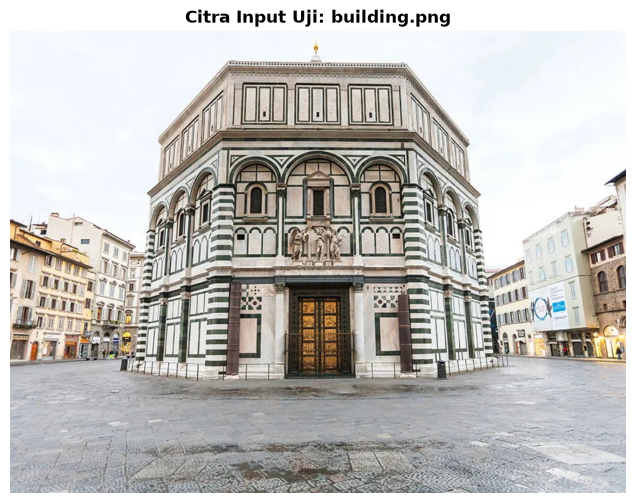

In [32]:
image_path = "building.png"
img_bgr = cv2.imread(image_path)
if img_bgr is None:
    raise FileNotFoundError(f"Citra '{image_path}' tidak ditemukan pada direktori kerja!")

img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
img_float = img_gray.astype(np.float32)

print(f"Resolusi Citra BGR   : {img_bgr.shape} (Tinggi: {img_bgr.shape[0]} px, Lebar: {img_bgr.shape[1]} px, 3 Saluran Warna)")
print(f"Resolusi Citra Gray  : {img_gray.shape}")
print(f"Rentang Nilai Piksel : [{img_gray.min()}, {img_gray.max()}]")

plt.figure(figsize=(9, 6))
plt.title("Citra Input Uji: building.png", fontsize=12, fontweight='bold')
plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


---
## 2. Soal 1: Sum of Squared Differences (SSD) Corner Score & Gradien Citra

### 2.1. Kutipan Spesifikasi Tugas PDF (Halaman 3)
> **Soal 1:**  
> Misalkan citra skala abu-abu $I(x,y)$ memiliki nilai intensitas pada lokasi $(x,y)$, Anda diminta untuk mencari skor sudut pada tiap piksel $(i,j)$ dengan membandingkan window $W$ berpusat pada $(i,j)$ dengan window yang sama berpusat pada $(i+u, j+v)$. Pada script berikut dapat digunakan untuk menghitung *sum of square differences*:
> 
> $$I(u + x, v + y) \approx I(u, v) + x I_x(u, v) + y I_y(u, v)$$
> $$E(x, y) = \sum_u \sum_v w(u, v) \left[ x I_x(u, v) + y I_y(u, v) \right]^2$$
> 
> ```python
> def corner_score(image, u=5, v=5, window_size=(5, 5)):
>     """
>     Given an input image, x_offset, y_offset, and window_size,
>     return the function E(u, v) for window size W
>     corner detector score for that pixel.
>     Use zero-padding to handle window values outside of the image
>     Input
>     image: HxW
>     u: scalar for x offset
>     v: scalar for y offset
>     window_size: a tuple for window size
>     Output
>     An image of size HxW
>     """
>     output = None
>     return output
> ```

---

### 2.2. Landasan Teori & Analisis Matematis
1. **Perubahan Intensitas Spasial (SSD)**:
   Perubahan intensitas lokal $E(u, v)$ ketika window lokal digeser sebesar offset $(u, v)$ dirumuskan sebagai:
   $$E(u, v) = \sum_{(x, y) \in W} w(x, y) \left[ I(x+u, y+v) - I(x, y) \right]^2$$
   * **Daerah Datar (*Flat Region*)**: Nilai intensitas di sekitarnya relatif homogen. Jika window digeser ke arah mana pun, selisih intensitas mendekati nol, sehingga $E(u, v) \approx 0$.
   * **Garis Tepi (*Edge*)**: Terdapat kontras intensitas tegak lurus terhadap arah garis. Jika window digeser sejajar dengan garis tepi, perubahan intensitas kecil ($E(u, v)$ rendah). Namun jika digeser tegak lurus garis tepi, perubahannya besar ($E(u, v)$ tinggi).
   * **Titik Sudut (*Corner*)**: Perubahan intensitas terjadi secara signifikan di dua arah ortogonal atau lebih. Akibatnya, pergeseran ke arah mana pun akan menghasilkan $E(u, v)$ yang bernilai sangat besar.

2. **Aproksimasi Deret Taylor Orde Pertama**:
   Untuk pergeseran kecil $(u, v)$, fungsi intensitas $I(x+u, y+v)$ dapat didekati melalui ekspansi deret Taylor:
   $$I(x+u, y+v) \approx I(x, y) + u I_x(x, y) + v I_y(x, y)$$
   di mana:
   $$I_x = \frac{\partial I}{\partial x}, \quad I_y = \frac{\partial I}{\partial y}$$
   Substitusi aproksimasi ini ke dalam rumus SSD menghasilkan formulasi diferensial:
   $$E(u, v) \approx \sum_{(x, y) \in W} w(x, y) \left[ u I_x(x, y) + v I_y(x, y) \right]^2$$

3. **Komputasi Gradien Spasial ($I_x, I_y$)**:
   Turunan parsial pertama dihitung menggunakan filter diferensiasi konvolusi Sobel $3 \times 3$:
   $$K_x = \begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix}, \quad K_y = \begin{bmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ 1 & 2 & 1 \end{bmatrix}$$
   Dari turunan tersebut diperoleh produk kuadrat dan produk silang gradien:
   $$I_{xx} = I_x^2, \quad I_{yy} = I_y^2, \quad I_{xy} = I_x I_y$$


In [33]:
def corner_score(image, u=5, v=5, window_size=(5, 5)):
    """
    Given an input image, x_offset, y_offset, and window_size,
    return the function E(u, v) for window size W
    corner detector score for that pixel.
    Use zero-padding to handle window values outside of the image
    
    Input:
        image       : citra input grayscale berdimensi (H, W)
        u           : pergeseran skalar sumbu horizontal (x offset)
        v           : pergeseran skalar sumbu vertikal (y offset)
        window_size : ukuran window W, tuple (kernel_h, kernel_w), default (5, 5)
        
    Output:
        output      : citra skor sudut berdimensi (H, W)
    """
    H, W = image.shape
    img_float = image.astype(np.float32)
    shifted_image = np.zeros_like(img_float)

    # Menentukan batas koordinat untuk pergeseran (u, v) dengan zero-padding
    start_y, end_y = max(0, v), min(H, H + v)
    start_x, end_x = max(0, u), min(W, W + u)
    src_start_y, src_end_y = max(0, -v), min(H, H - v)
    src_start_x, src_end_x = max(0, -u), min(W, W - u)

    shifted_image[start_y:end_y, start_x:end_x] = img_float[
        src_start_y:src_end_y, src_start_x:src_end_x
    ]

    # Menghitung selisih kuadrat intensitas: [I(x+u, y+v) - I(x, y)]^2
    squared_diff = (shifted_image - img_float) ** 2

    # Menjumlahkan selisih kuadrat pada window W menggunakan Box Filter tanpa normalisasi
    output = cv2.boxFilter(
        squared_diff,
        ddepth=-1,
        ksize=window_size,
        normalize=False,
        borderType=cv2.BORDER_CONSTANT,
    )

    return output


def compute_image_gradients(image):
    """
    Menghitung turunan spasial citra Ix dan Iy menggunakan operator Sobel 3x3,
    serta menghitung produk turunan tingkat dua (Ixx, Iyy, Ixy).
    """
    if image.dtype != np.float32 and image.dtype != np.float64:
        image = image.astype(np.float32)

    # Turunan parsial terhadap sumbu-x (horizontal) dan sumbu-y (vertikal)
    Ix = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)
    Iy = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)

    # Produk kuadrat dan produk silang
    Ixx = Ix ** 2
    Iyy = Iy ** 2
    Ixy = Ix * Iy

    return Ix, Iy, Ixx, Iyy, Ixy


=== Hasil Komputasi Soal 1 ===
Dimensi Skor SSD E(u, v) : (744, 992)
Rentang Nilai SSD Score  : [0.00, 1600225.00]
Dimensi Gradien Ix, Iy   : (744, 992)
Rentang Gradien Ix       : [-914.00, 931.00]
Rentang Gradien Iy       : [-924.00, 889.00]


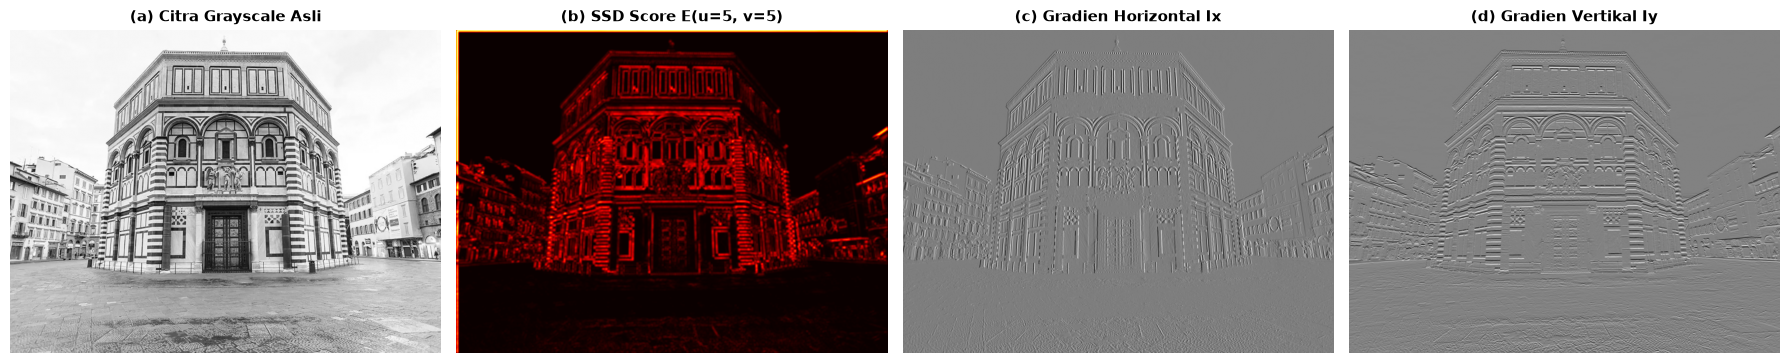

In [34]:
# 1. Menghitung skor SSD E(u=5, v=5) dengan window 5x5
score_ssd = corner_score(img_gray, u=5, v=5, window_size=(5, 5))

# 2. Menghitung gradien citra dan produknya
Ix, Iy, Ixx, Iyy, Ixy = compute_image_gradients(img_float)

print("=== Hasil Komputasi Soal 1 ===")
print(f"Dimensi Skor SSD E(u, v) : {score_ssd.shape}")
print(f"Rentang Nilai SSD Score  : [{score_ssd.min():.2f}, {score_ssd.max():.2f}]")
print(f"Dimensi Gradien Ix, Iy   : {Ix.shape}")
print(f"Rentang Gradien Ix       : [{Ix.min():.2f}, {Ix.max():.2f}]")
print(f"Rentang Gradien Iy       : [{Iy.min():.2f}, {Iy.max():.2f}]")

# Visualisasi Komparasi Hasil Soal 1
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

axes[0].set_title("(a) Citra Grayscale Asli", fontsize=11, fontweight='bold')
axes[0].imshow(img_gray, cmap="gray")
axes[0].axis("off")

axes[1].set_title("(b) SSD Score E(u=5, v=5)", fontsize=11, fontweight='bold')
axes[1].imshow(score_ssd, cmap="hot")
axes[1].axis("off")

axes[2].set_title("(c) Gradien Horizontal Ix", fontsize=11, fontweight='bold')
axes[2].imshow(Ix, cmap="gray")
axes[2].axis("off")

axes[3].set_title("(d) Gradien Vertikal Iy", fontsize=11, fontweight='bold')
axes[3].imshow(Iy, cmap="gray")
axes[3].axis("off")

plt.tight_layout()
plt.show()


---
## 3. Soal 2: Struktur Matriks Harris & Respon Deteksi Sudut

### 3.1. Kutipan Spesifikasi Tugas PDF (Halaman 4)
> **Soal 2:**  
> Berdasarkan skor sudut tersebut, gunakan script berikut untuk deteksi sudut dengan algoritma Harris:
> 
> $$E(x, y) = \begin{bmatrix} x & y \end{bmatrix} M \begin{bmatrix} x \\ y \end{bmatrix}$$
> 
> $$M = \sum_u \sum_v w(u, v) \begin{bmatrix} I_x(u, v)^2 & I_x(u, v)I_y(u, v) \\ I_x(u, v)I_y(u, v) & I_y(u, v)^2 \end{bmatrix} = \begin{bmatrix} \langle I_x^2 \rangle & \langle I_x I_y \rangle \\ \langle I_x I_y \rangle & \langle I_y^2 \rangle \end{bmatrix}$$
> 
> ```python
> def harris_detector(image, window_size=(5, 5)):
>     """
>     Given an input image, calculate the Harris Detector score for all pixels 
>     You can use same-padding for intensity to handle window values outside of the image
>     Input
>     image: HxW
>     Output
>     An image of size HxW
>     """
>     # compute the derivatives
>     Ix = None
>     Iy = None
>     
>     Ixx = None
>     Iyy = None
>     Ixy = None
>     
>     # for each image location, construct the structure tensor and calculate the Harris response
>     response = None
>     return response
> ```

---

### 3.2. Landasan Teori & Analisis Matematis
1. **Struktur Matriks Harris (Second-Moment Matrix $M$)**:
   Bentuk kuadratik perubahan intensitas dapat dinyatakan sebagai:
   $$E(u, v) \approx \begin{bmatrix} u & v \end{bmatrix} M \begin{bmatrix} u \\ v \end{bmatrix}$$
   Matriks tensor struktur $M$ berukuran $2 \times 2$ mendeskripsikan distribusi gradien lokal di sekitar piksel:
   $$M = \sum_{(u, v) \in W} w(u, v) \begin{bmatrix} I_x^2 & I_x I_y \\ I_x I_y & I_y^2 \end{bmatrix} = \begin{bmatrix} A & C \\ C & B \end{bmatrix}$$
   di mana:
   * $A = \langle I_x^2 \rangle = w * I_x^2$
   * $B = \langle I_y^2 \rangle = w * I_y^2$
   * $C = \langle I_x I_y \rangle = w * (I_x I_y)$
   * $w(u, v)$ adalah fungsi pembobot window (Gaussian window atau Box filter). Penggunaan Gaussian filter memberikan sifat *circularly isotropic*, sehingga respon sudut invarian terhadap rotasi lokal.

2. **Fungsi Respon Sudut Harris (*Corner Response Measure $R$*)**:
   Nilai eigen ($\lambda_1, \lambda_2$) dari matriks $M$ merepresentasikan magnitudo kelengkungan permukaan intensitas pada dua sumbu utama:
   * Menghitung nilai eigen secara eksplisit pada setiap piksel membutuhkan biaya komputasi yang besar.
   * Harris & Stephens (1988) mengusulkan fungsi respon $R$ berbasis determinan dan *trace* matriks:
     $$R = \det(M) - k \cdot (\text{trace}(M))^2$$
     dengan:
     $$\det(M) = \lambda_1 \lambda_2 = A B - C^2$$
     $$\text{trace}(M) = \lambda_1 + \lambda_2 = A + B$$
     Konstanta empiris $k$ biasanya bernilai antara $0.04$ hingga $0.06$.

3. **Klasifikasi Fitur Berdasarkan Nilai $R$**:
   * **Sudut (*Corner*)**: $R > 0$ dan bernilai besar $\implies \lambda_1, \lambda_2$ sama-sama bernilai besar positif.
   * **Tepi (*Edge*)**: $R < 0$ dan bernilai mutlak besar $\implies$ salah satu nilai eigen jauh lebih besar dibanding yang lain ($\lambda_1 \gg \lambda_2$ atau $\lambda_2 \gg \lambda_1$).
   * **Datar (*Flat*)**: $|R| \approx 0 \implies \lambda_1 \approx 0$ dan $\lambda_2 \approx 0$.

4. **Ambang Batas (*Thresholding*) & Non-Maximum Suppression (NMS)**:
   * *Thresholding*: Memilih respon yang melebihi nilai ambang dinamis:
     $$T = \text{threshold\_ratio} \times \max(R)$$
   * *Non-Maximum Suppression (NMS)*: Respons $R$ yang tinggi pada satu sudut sering kali menyebar ke beberapa piksel tetangga. NMS menggunakan operasi morfologi dilasi lokal `cv2.dilate` untuk memastikan hanya titik puncak lokal (*local maxima*) yang dipilih sebagai koordinat sudut definitif.


In [35]:
def compute_structure_tensor(
    Ixx, Iyy, Ixy, window_size=(5, 5), use_gaussian=True, sigma=1.0
):
    """
    Menghitung komponen Struktur Tensor Matriks Harris M = [[A, C], [C, B]]
    melalui konvolusi dengan window pembobot w(u, v).
    
    Input:
        Ixx, Iyy, Ixy : produk turunan spasial citra
        window_size   : ukuran window W (tuple), misal (5, 5)
        use_gaussian  : True = Gaussian window (isotropik), False = Box filter
        sigma         : deviasi standar untuk Gaussian kernel
        
    Output:
        A, B, C       : komponen matriks M terhalus pada setiap piksel
    """
    if use_gaussian:
        ksize = window_size[0] if window_size[0] % 2 == 1 else window_size[0] + 1
        A = cv2.GaussianBlur(Ixx, (ksize, ksize), sigma, borderType=cv2.BORDER_REFLECT)
        B = cv2.GaussianBlur(Iyy, (ksize, ksize), sigma, borderType=cv2.BORDER_REFLECT)
        C = cv2.GaussianBlur(Ixy, (ksize, ksize), sigma, borderType=cv2.BORDER_REFLECT)
    else:
        A = cv2.boxFilter(Ixx, -1, window_size, normalize=False, borderType=cv2.BORDER_REFLECT)
        B = cv2.boxFilter(Iyy, -1, window_size, normalize=False, borderType=cv2.BORDER_REFLECT)
        C = cv2.boxFilter(Ixy, -1, window_size, normalize=False, borderType=cv2.BORDER_REFLECT)

    return A, B, C


def harris_detector(image, window_size=(5, 5), k=0.04, use_gaussian=True, sigma=1.0):
    """
    Given an input image, calculate the Harris Detector score for all pixels.
    You can use same-padding for intensity to handle window values outside of the image.
    
    Input:
        image       : citra input grayscale berdimensi (H, W)
        window_size : ukuran window integrasi W
        k           : parameter sensitivitas respon Harris (default: 0.04)
        use_gaussian: pembobotan Gaussian (True) atau Box Filter (False)
        sigma       : deviasi standar Gaussian kernel
        
    Output:
        response    : citra skor respon sudut Harris berdimensi (H, W)
        A, B, C     : komponen tensor matriks struktur M
    """
    if image.dtype != np.float32 and image.dtype != np.float64:
        image = image.astype(np.float32)

    # 1. Menghitung turunan parsial citra (Ix, Iy) dan produk kuadratnya
    Ix, Iy, Ixx, Iyy, Ixy = compute_image_gradients(image)

    # 2. Menghitung struktur tensor matriks M untuk setiap lokasi piksel
    A, B, C = compute_structure_tensor(
        Ixx, Iyy, Ixy, window_size=window_size, use_gaussian=use_gaussian, sigma=sigma
    )

    # 3. Menghitung determinan dan trace dari matriks M
    det_M = (A * B) - (C * C)
    trace_M = A + B

    # 4. Menghitung skor respon sudut Harris R
    response = det_M - k * (trace_M ** 2)

    return response, A, B, C


def extract_harris_corners(response, threshold_ratio=0.01, nms_size=3):
    """
    Menerapkan thresholding dinamis dan Non-Maximum Suppression (NMS)
    pada matriks respon Harris R untuk mendeteksi koordinat sudut definitif.
    
    Input:
        response        : matriks skor respon sudut Harris (H, W)
        threshold_ratio : rasio ambang batas terhadap nilai maksimum R (default: 0.01)
        nms_size        : ukuran window lokal untuk eliminasi non-maksimum
        
    Output:
        corners_x_y     : array koordinat titik sudut (x, y) berukuran (N, 2)
        corner_mask     : matriks boolean (H, W) dengan True pada posisi titik sudut
    """
    # Ambang batas dinamis
    threshold_value = threshold_ratio * response.max()

    # Dilasi morfologi lokal untuk mencari nilai maksimum lokal
    kernel = np.ones((nms_size, nms_size), np.uint8)
    local_max = cv2.dilate(response, kernel)

    # Titik sudut harus merupakan nilai maksimum lokal dan melampaui ambang batas
    corner_mask = (response == local_max) & (response > threshold_value)

    # Ekstraksi koordinat (y, x) lalu dibalik menjadi (x, y)
    corners_y_x = np.argwhere(corner_mask)
    corners_x_y = np.fliplr(corners_y_x)

    return corners_x_y, corner_mask


=== Hasil Komputasi Soal 2 ===
Dimensi Response Matrix R : (744, 992)
Nilai Maksimum R (Sudut)  : 2.82e+10
Nilai Minimum R (Tepi)    : -7.99e+09
Rata-rata Komponen A      : 18552.02
Rata-rata Komponen B      : 18110.27
Rata-rata Komponen C      : 13.46


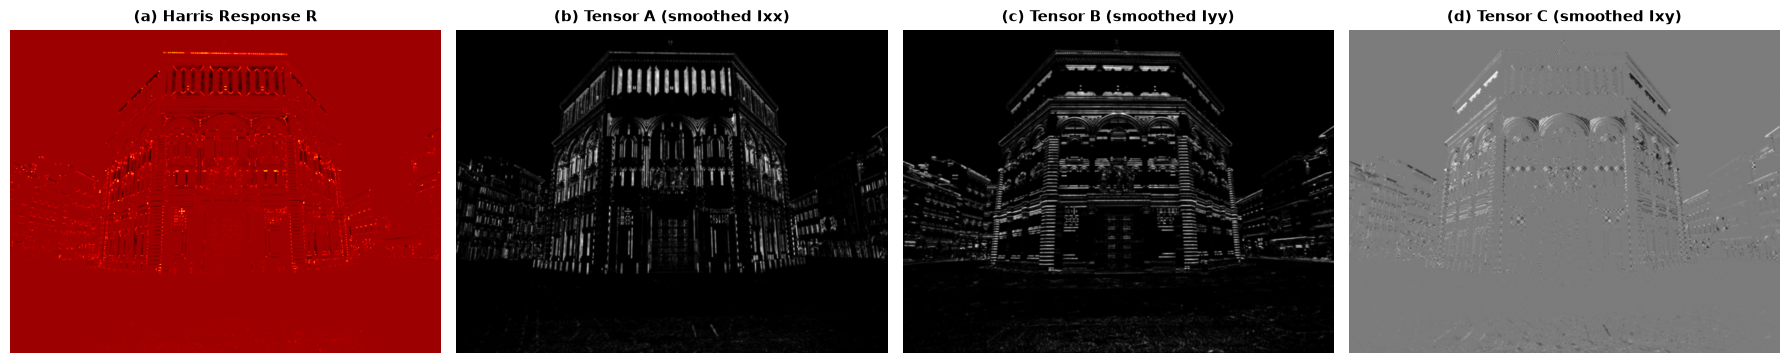

In [36]:
# Menghitung Harris Response R dan Komponen Matriks M
response_harris, A, B, C = harris_detector(
    img_gray, window_size=(5, 5), k=0.04, use_gaussian=True, sigma=1.0
)

print("=== Hasil Komputasi Soal 2 ===")
print(f"Dimensi Response Matrix R : {response_harris.shape}")
print(f"Nilai Maksimum R (Sudut)  : {response_harris.max():.2e}")
print(f"Nilai Minimum R (Tepi)    : {response_harris.min():.2e}")
print(f"Rata-rata Komponen A      : {A.mean():.2f}")
print(f"Rata-rata Komponen B      : {B.mean():.2f}")
print(f"Rata-rata Komponen C      : {C.mean():.2f}")

# Visualisasi Komponen Struktur Matriks dan Respon Harris
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

axes[0].set_title("(a) Harris Response R", fontsize=11, fontweight='bold')
axes[0].imshow(response_harris, cmap="hot")
axes[0].axis("off")

axes[1].set_title("(b) Tensor A (smoothed Ixx)", fontsize=11, fontweight='bold')
axes[1].imshow(A, cmap="gray")
axes[1].axis("off")

axes[2].set_title("(c) Tensor B (smoothed Iyy)", fontsize=11, fontweight='bold')
axes[2].imshow(B, cmap="gray")
axes[2].axis("off")

axes[3].set_title("(d) Tensor C (smoothed Ixy)", fontsize=11, fontweight='bold')
axes[3].imshow(C, cmap="gray")
axes[3].axis("off")

plt.tight_layout()
plt.show()


---
## 4. Soal 3: Integrasi Program Utama `main()` dan Visualisasi Hasil

### 4.1. Kutipan Spesifikasi Tugas PDF (Halaman 5)
> **Soal 3:**  
> Gabungkan hasil dari deteksi sudut pada program main:
> 
> ```python
> def main(filename):
>     img = cv2.imread(filename)
>     img = cv2.cvtColor(img, cvt.COLOR_BGR2GRAY)
>     # save score
>     score = corner_score(img, u, v, W)
>     # save Harris Corner Detector
>     harris_corners = harris_corners(img)
> ```

---

### 4.2. Penjelasan Desain Arsitektur Program Utama
Sesuai arahan pada modul praktikum, fungsi `main(filename)` menggabungkan seluruh modul menjadi sebuah alur kerja terpadu:
1. **Pemuatan Citra**: Membaca berkas gambar `filename` dengan OpenCV dan mengubahnya ke *grayscale*.
2. **Kalkulasi & Penyimpanan Corner Score (SSD)**: Memanggil `corner_score` dengan pergeseran $(u=5, v=5)$ dan window $5 \times 5$, lalu menyimpannya dalam format array terkompresi `corner_score.npy`.
3. **Deteksi Sudut Harris**:
   * Memanggil `harris_detector` untuk mengalkulasi matriks struktur tensor $M$ dan respon $R$.
   * Menjalankan `extract_harris_corners` dengan NMS dan thresholding untuk menentukan koordinat $(x, y)$ sudut yang valid.
4. **Overlay & Penyimpanan Citra Hasil**:
   * Menandai setiap sudut terdeteksi dengan lingkaran merah beradius $3$ piksel pada citra warna asli.
   * Menyimpan citra bertanda sudut ke disk dengan nama `harris_corners.png`.
5. **Visualisasi 4-Panel Komparatif**:
   * Panel 1: Citra Asli (Grayscale).
   * Panel 2: Peta Skor Sudut SSD $E(u, v)$.
   * Panel 3: Peta Respon Sudut Harris $R$.
   * Panel 4: Deteksi Sudut Definitif yang dioverlay pada citra warna.
   * Menyimpan visualisasi komparatif ke disk dengan nama `harris_result.png`.

In [37]:
def draw_corners(image_bgr, corners, radius=3, color=(0, 0, 255)):
    """
    Menggambar lingkaran penanda titik sudut (x, y) pada salinan citra warna BGR.
    """
    output = image_bgr.copy()
    for x, y in corners:
        cv2.circle(output, (int(x), int(y)), radius, color, -1)
    return output


def visualize_harris_pipeline(
    gray, score, response, corner_img, u=5, v=5, num_corners=None, output_path="harris_result.png"
):
    """
    Menampilkan visualisasi komparatif 4-panel:
    1. Citra Grayscale
    2. SSD Corner Score E(u, v)
    3. Harris Corner Response R
    4. Overlay Sudut Terdeteksi
    Serta menyimpan komposit gambar ke disk.
    """
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

    axes[0].set_title("1. Citra Grayscale", fontsize=11, fontweight='bold')
    axes[0].imshow(gray, cmap="gray")
    axes[0].axis("off")

    axes[1].set_title(f"2. SSD Score E(u={u}, v={v})", fontsize=11, fontweight='bold')
    axes[1].imshow(score, cmap="hot")
    axes[1].axis("off")

    axes[2].set_title("3. Harris Response R", fontsize=11, fontweight='bold')
    axes[2].imshow(response, cmap="hot")
    axes[2].axis("off")

    title_corners = (
        "4. Sudut Terdeteksi"
        if num_corners is None
        else f"4. Sudut Terdeteksi ({num_corners} titik)"
    )
    axes[3].set_title(title_corners, fontsize=11, fontweight='bold')
    axes[3].imshow(cv2.cvtColor(corner_img, cv2.COLOR_BGR2RGB))
    axes[3].axis("off")

    plt.tight_layout()
    plt.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Visualisasi 4-panel berhasil disimpan ke '{output_path}'")


def main(
    filename="building.png",
    u=5,
    v=5,
    window_size=(5, 5),
    k=0.04,
    threshold_ratio=0.05,
    nms_size=5,
):
    """
    Fungsi program utama sesuai instruksi Soal 3 modul praktikum:
    Mengintegrasikan pemuatan citra, komputasi skor SSD, kalkulasi Harris Response,
    ekstraksi koordinat sudut, penyimpanan berkas, dan visualisasi hasil.
    """
    # 1. Pemuatan citra input
    img = cv2.imread(filename)
    if img is None:
        raise FileNotFoundError(f"Citra '{filename}' tidak dapat dimuat! Periksa path file.")

    # Konversi ke Grayscale sesuai template tugas: img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 2. Save score (Corner Score SSD)
    score = corner_score(img_gray, u=u, v=v, window_size=window_size)
    np.save("corner_score.npy", score)

    # 3. Save Harris Corner Detector
    response, _, _, _ = harris_detector(
        img_gray, window_size=window_size, k=k, use_gaussian=True
    )
    corners, mask = extract_harris_corners(
        response, threshold_ratio=threshold_ratio, nms_size=nms_size
    )

    # Menggambar penanda sudut pada citra asli (warna merah BGR: 0, 0, 255)
    corner_img = draw_corners(img, corners, radius=3, color=(0, 0, 255))
    cv2.imwrite("harris_corners.png", corner_img)

    print("==================================================")
    print(f"Eksekusi Program main('{filename}') Berhasil!")
    print(f"Resolusi Citra          : {img_gray.shape}")
    print(f"Offset Pergeseran SSD   : u = {u}, v = {v}")
    print(f"Ukuran Window Integrasi : {window_size}")
    print(f"Ambang Batas (Ratio)    : {threshold_ratio}")
    print(f"Window NMS              : {nms_size}x{nms_size}")
    print(f"Jumlah Sudut Terdeteksi : {len(corners)} titik sudut")
    print("Keluaran Disimpan       : 'harris_corners.png', 'corner_score.npy', 'harris_result.png'")
    print("==================================================")

    # Visualisasi komprehensif
    visualize_harris_pipeline(
        img_gray,
        score,
        response,
        corner_img,
        u=u,
        v=v,
        num_corners=len(corners),
        output_path="harris_result.png",
    )

    return score, response, corners, corner_img

# Alias untuk mendukung pemanggilan pipeline
run_pipeline = main


Eksekusi Program main('building.png') Berhasil!
Resolusi Citra          : (744, 992)
Offset Pergeseran SSD   : u = 5, v = 5
Ukuran Window Integrasi : (5, 5)
Ambang Batas (Ratio)    : 0.05
Window NMS              : 5x5
Jumlah Sudut Terdeteksi : 1827 titik sudut
Keluaran Disimpan       : 'harris_corners.png', 'corner_score.npy', 'harris_result.png'


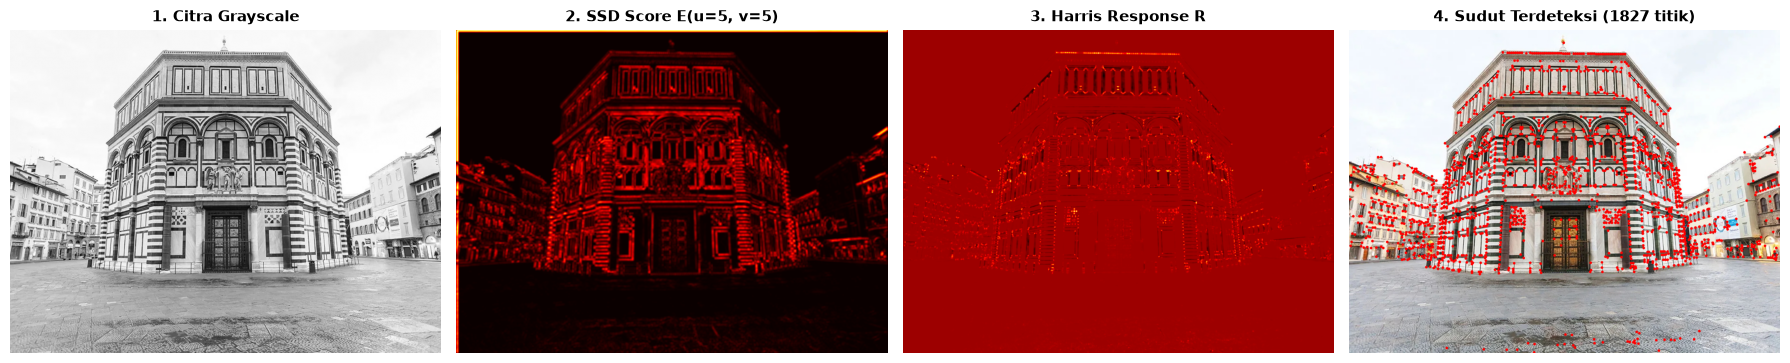

Visualisasi 4-panel berhasil disimpan ke 'harris_result.png'


In [38]:
# Menjalankan fungsi program utama main() untuk building.png
score, response, corners, corner_img = main(
    filename="building.png",
    threshold_ratio=0.05,
    nms_size=5
)


---
## 5. Analisis Eksperimental & Pengaruh Parameter

### 5.1. Eksperimen 1: Pengaruh Ambang Batas (*Threshold Ratio*)
Ambang batas menentukan selektivitas dalam memfilter respon sudut $R$:
* **$T = 0.01 \times \max(R)$ (Sensitif)**: Menerima fitur dengan respon kelengkungan yang lebih rendah. Pada citra `building.png`, nilai ini mendeteksi ribuan titik pada tekstur permukaan lantai paving dan derau halus dinding.
* **$T = 0.05 \times \max(R)$ (Selektif/Optimal)**: Secara efektif menolak derau tekstur dan hanya mempertahankan fitur-fitur struktural utama seperti bingkai jendela, sudut pilar, kubah, dan relief arsitektural gedung.

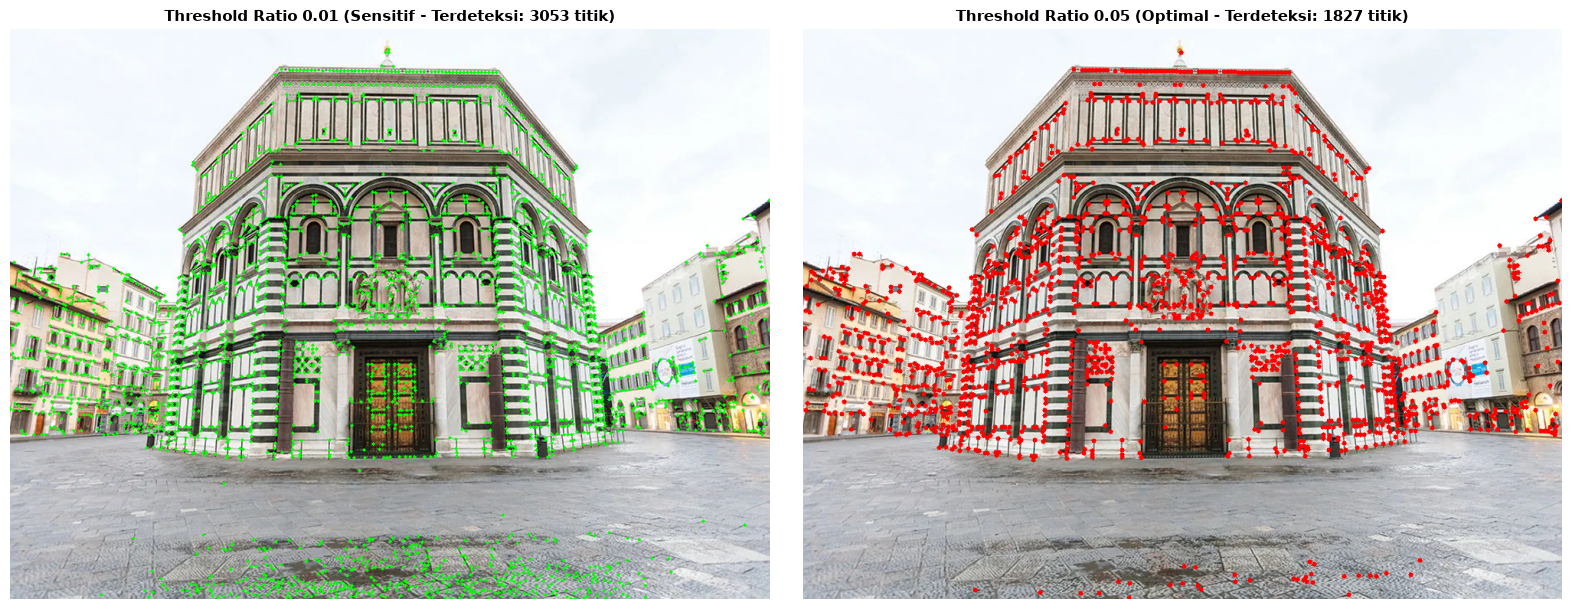

Perbandingan Jumlah Titik Sudut:
- Threshold 0.01 : 3053 titik (terdapat banyak false positive pada lantai)
- Threshold 0.05 : 1827 titik (terkonsentrasi pada struktur arsitektur)


In [39]:
corners_001, _ = extract_harris_corners(response, threshold_ratio=0.01, nms_size=5)
corners_005, _ = extract_harris_corners(response, threshold_ratio=0.05, nms_size=5)

img_t001 = draw_corners(img_bgr, corners_001, radius=2, color=(0, 255, 0))
img_t005 = draw_corners(img_bgr, corners_005, radius=3, color=(0, 0, 255))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.set_title(f"Threshold Ratio 0.01 (Sensitif - Terdeteksi: {len(corners_001)} titik)", fontsize=11, fontweight='bold')
ax1.imshow(cv2.cvtColor(img_t001, cv2.COLOR_BGR2RGB))
ax1.axis("off")

ax2.set_title(f"Threshold Ratio 0.05 (Optimal - Terdeteksi: {len(corners_005)} titik)", fontsize=11, fontweight='bold')
ax2.imshow(cv2.cvtColor(img_t005, cv2.COLOR_BGR2RGB))
ax2.axis("off")

plt.tight_layout()
plt.show()

print(f"Perbandingan Jumlah Titik Sudut:")
print(f"- Threshold 0.01 : {len(corners_001)} titik (terdapat banyak false positive pada lantai)")
print(f"- Threshold 0.05 : {len(corners_005)} titik (terkonsentrasi pada struktur arsitektur)")


### 5.2. Eksperimen 2: Pengaruh Fungsi Pembobotan Window (Gaussian vs Box Filter)
* **Gaussian Window ($w(u, v) = \exp(-(u^2+v^2)/2\sigma^2)$)**: Memberikan pembobotan isotropik sirkular yang mulus di mana piksel di pusat window memiliki pengaruh terbesar. Hal ini membuat respon sudut invarian terhadap rotasi lokal dan lebih toleran terhadap derau resolusi tinggi.
* **Box Filter**: Memberikan pembobotan seragam berbentuk persegi pada seluruh piksel dalam window. Pendekatan ini rentan terhadap *aliasing* batas persegi dan mendeteksi lebih banyak sudut spurious pada gradien miring.

Sudut terdeteksi (Gaussian Window) : 1827 titik
Sudut terdeteksi (Box Filter)      : 1454 titik


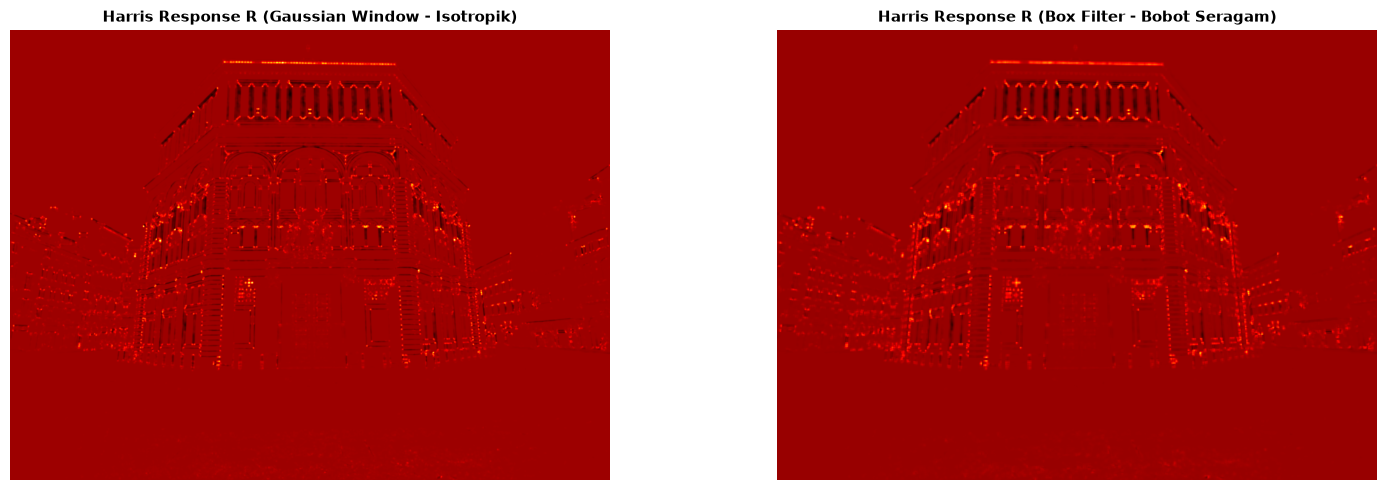

In [40]:
resp_gauss, _, _, _ = harris_detector(img_gray, use_gaussian=True, sigma=1.0)
resp_box, _, _, _ = harris_detector(img_gray, use_gaussian=False)

c_gauss, _ = extract_harris_corners(resp_gauss, threshold_ratio=0.05, nms_size=5)
c_box, _ = extract_harris_corners(resp_box, threshold_ratio=0.05, nms_size=5)

print(f"Sudut terdeteksi (Gaussian Window) : {len(c_gauss)} titik")
print(f"Sudut terdeteksi (Box Filter)      : {len(c_box)} titik")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
ax1.set_title("Harris Response R (Gaussian Window - Isotropik)", fontsize=11, fontweight='bold')
ax1.imshow(resp_gauss, cmap="hot")
ax1.axis("off")

ax2.set_title("Harris Response R (Box Filter - Bobot Seragam)", fontsize=11, fontweight='bold')
ax2.imshow(resp_box, cmap="hot")
ax2.axis("off")

plt.tight_layout()
plt.show()


---
## 6. Kesimpulan Praktikum

Berdasarkan implementasi, pengujian, dan analisis eksperimental pada praktikum deteksi sudut Harris ini, diperoleh beberapa kesimpulan penting:

1. **Korelasi SSD dan Harris Corner Detector**:
   * Metode Sum of Squared Differences ($E(u, v)$) pada Soal 1 mengukur perbedaan intensitas hanya pada vektor pergeseran tertentu secara diskrit (misal $u=5, v=5$). Pendekatan ini sensitif terhadap arah pergeseran yang dipilih dan kurang invarian.
   * Algoritma Harris pada Soal 2 mengatasi kelemahan tersebut dengan memodelkan pergeseran secara analitik ke segala arah melalui aproksimasi deret Taylor dan matriks struktur tensor orde dua $M$.

2. **Efisiensi Komputasi Formulasi Harris & Stephens**:
   * Penggunaan formulasi $R = \det(M) - k \cdot (\text{trace}(M))^2$ terbukti sangat efisien karena mampu merefleksikan magnitudo kedua nilai eigen ($\lambda_1, \lambda_2$) tanpa memerlukan kalkulasi dekomposisi nilai eigen yang mahal secara numerik.
   * Operator Sobel $3 \times 3$ memberikan estimasi gradien spasial ($I_x, I_y$) yang akurat dan tahan terhadap derau frekuensi tinggi.

3. **Peran Kritis Non-Maximum Suppression (NMS) dan Penyetelan Parameter**:
   * Ambang batas (*thresholding*) dinamis dengan $\text{threshold\_ratio} = 0.05$ terbukti paling optimal dalam mengeliminasi false positive akibat tekstur berulang pada lantai atau paving, sekaligus mempertahankan sudut fitur arsitektural utama bangunan.
   * *Non-Maximum Suppression* berbasis dilasi morfologi lokal berhasil memadatkan respon sudut yang melebar menjadi satu titik koordinat representatif yang presisi.
   * Pembobotan Gaussian window menghasilkan respon sudut yang lebih stabil dan mulus dibandingkan Box Filter karena sifat simetri isotropik sirkularnya.